## Analysis: Understanding Customer Feedback Using TF-IDF

##Name:
Reham Mohammed Abod



#Load the Amazon Data


---



In [ ]:
import pandas as pd
# تحميل البيانات / Load dataset
df = pd.read_csv("amazon.csv")

### Importing Libraries



In [ ]:
# استيراد المكتبات الأساسية لمعالجة البيانات
# Import basic libraries for data handling
# =========================================

import pandas as pd   # للتعامل مع البيانات (DataFrames)
import numpy as np    # للعمليات الحسابية

# مكتبات الرسم (اختياري)
# Visualization libraries (optional)
# =========================================

import matplotlib.pyplot as plt   # لرسم الرسومات البيانية

# مكتبة التعبيرات المنتظمة (regex)
# Regular expressions for text cleaning
# =========================================

import re   # لإزالة الرموز وتنظيف النصوص

# مكتبات معالجة اللغة الطبيعية
# Natural Language Processing (NLP)
# =========================================

import nltk   # مكتبة NLP

from nltk.corpus import stopwords           # الكلمات الشائعة
from nltk.tokenize import word_tokenize     # تقسيم النص إلى كلمات
from nltk.stem import WordNetLemmatizer     # إرجاع الكلمات لأصلها

# أدوات إضافية
# Additional tools
# =========================================

from collections import Counter   # لحساب تكرار الكلمات
from wordcloud import WordCloud   # لإنشاء WordCloud

# تحميل بيانات NLTK (مرة واحدة فقط)
# Download required NLTK datasets
# =========================================

nltk.download('punkt')       # لتقسيم النص
nltk.download('stopwords')   # الكلمات الشائعة
nltk.download('wordnet')     # للـ Lemmatization
nltk.download('omw-1.4')     # دعم إضافي للـ Lemmatization

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


True

 Understand Text Data

In [ ]:
# =========================================
# Sample the dataset
# =========================================

# أخذ عينة من البيانات (5000 مراجعة)
sample_df = df.sample(min(5000, len(df)), random_state=42)

# اختيار عمود النص
text = sample_df['review_content']

# حذف القيم الفارغة
text = text.dropna()

# =========================================
# Explore the data
# =========================================

# عرض شكل البيانات
print("Text shape:")
print(text.shape)

# عرض أول 5 مراجعات (Before)
print("\nSample of raw text:")
print(text.head())

Text shape:
(1465,)

Sample of raw text:
976    first i would like to comment on the tab marke...
175    Good,Its working is very nice with pc. Easy to...
275    Ok,Very disappointedRange is not good it doesn...
548    Used guiding stickers but in those places bubb...
869    Easy to use,It's good and useful,Had been usin...
Name: review_content, dtype: object


In [ ]:
print("\nExample review:")
print(text.iloc[0])


Example review:
first i would like to comment on the tab market of India. the most peculiar thing I have seen in India is, when a particular product is aimed towards students or education suddenly corporations go out of their way to milk money and under deliver as much as possible. it is exactly opposite to how students are given access to technology in the USA. you watch the prices of chromebooks, tablets, back to school offers in the US and compare them to India and it feels extremely unbalanced. after the pandemic there was a huge surge in the tab market and tier 1 brands started delivering garbage for 20000 rupees. snapdragon 400, old mediatek, 4gb ram, abysmal non ips screen for 20k just to mint money and take advantage of pandemic scenario and the circumstances of students. THIS TABLET BRINGS THE REVOLUTION.I am no student, but bought this for day to day use and I am an user of the normal big bezel 7th gen iPad, so my review will be comparative in nature. also i bought this at 2

##Text Cleaning

🟢 a. Normalize Text (Lowercase)

In [ ]:
# =========================================
# BEFORE (قبل التحويل إلى حروف صغيرة)
# =========================================
print("Before Lowercase:")
print(text.head())

# =========================================
# Apply Lowercase
# تحويل النص إلى حروف صغيرة لتوحيد الكلمات
# Convert text to lowercase to make words consistent
# =========================================
text = text.str.lower()

# =========================================
# AFTER (بعد التحويل)
# =========================================
print("\nAfter Lowercase:")
print(text.head())

Before Lowercase:
976    first i would like to comment on the tab marke...
175    Good,Its working is very nice with pc. Easy to...
275    Ok,Very disappointedRange is not good it doesn...
548    Used guiding stickers but in those places bubb...
869    Easy to use,It's good and useful,Had been usin...
Name: review_content, dtype: object

After Lowercase:
976    first i would like to comment on the tab marke...
175    good,its working is very nice with pc. easy to...
275    ok,very disappointedrange is not good it doesn...
548    used guiding stickers but in those places bubb...
869    easy to use,it's good and useful,had been usin...
Name: review_content, dtype: object


🟢 b. Remove Punctuation

In [ ]:
# =========================================
# BEFORE (قبل إزالة الرموز)
# =========================================
print("Before Removing Punctuation:")
print(text.head())

# =========================================
# Remove punctuation
# إزالة علامات الترقيم لتقليل الضوضاء في النص
# Remove punctuation to reduce noise in text
# =========================================
text = text.str.replace(r'[^\w\s]', '', regex=True)

# =========================================
# AFTER (بعد الإزالة)
# =========================================
print("\nAfter Removing Punctuation:")
print(text.head())

Before Removing Punctuation:
976    first i would like to comment on the tab marke...
175    good,its working is very nice with pc. easy to...
275    ok,very disappointedrange is not good it doesn...
548    used guiding stickers but in those places bubb...
869    easy to use,it's good and useful,had been usin...
Name: review_content, dtype: object

After Removing Punctuation:
976    first i would like to comment on the tab marke...
175    goodits working is very nice with pc easy to i...
275    okvery disappointedrange is not good it doesnt...
548    used guiding stickers but in those places bubb...
869    easy to useits good and usefulhad been using t...
Name: review_content, dtype: object


🟢 c. Remove Stopwords

In [ ]:
# تحميل كلمات التوقف
# Load stopwords
from nltk.corpus import stopwords
stop_words = set(stopwords.words('english'))

print("="*50)

# =========================================
# BEFORE (قبل حذف الكلمات الشائعة)
# =========================================
print("Before Removing Stopwords:")
print(text.head())

# =========================================
# Remove stopwords
# حذف الكلمات الشائعة مثل (the, is, and)
# Remove common words that don't add meaning
# =========================================
text = text.apply(lambda x: " ".join([word for word in x.split() if word not in stop_words]))

# =========================================
# AFTER
# =========================================
print("\nAfter Removing Stopwords:")
print(text.head())

Before Removing Stopwords:
976    first i would like to comment on the tab marke...
175    goodits working is very nice with pc easy to i...
275    okvery disappointedrange is not good it doesnt...
548    used guiding stickers but in those places bubb...
869    easy to useits good and usefulhad been using t...
Name: review_content, dtype: object

After Removing Stopwords:
976    first would like comment tab market india pecu...
175    goodits working nice pc easy install connected...
275    okvery disappointedrange good doesnt catch lit...
548    used guiding stickers places bubbles formed sh...
869    easy useits good usefulhad using quite sometim...
Name: review_content, dtype: object


#### Tokenization

In [ ]:
# Convert text -> list of words
# تحويل النص إلى قائمة كلمات

from nltk.tokenize import word_tokenize

tokens = text.apply(word_tokenize)

print(tokens.head())

976    [first, would, like, comment, tab, market, ind...
175    [goodits, working, nice, pc, easy, install, co...
275    [okvery, disappointedrange, good, doesnt, catc...
548    [used, guiding, stickers, places, bubbles, for...
869    [easy, useits, good, usefulhad, using, quite, ...
Name: review_content, dtype: object


هنا الفكرة تحويل النص الى قائمة كلمات

Lemmatization

In [ ]:
# تحويل الكلمات إلى شكلها الصحيح (الأفضل)

from nltk.stem import WordNetLemmatizer

lemmatizer = WordNetLemmatizer()

tokens_lemma = tokens.apply(lambda x: [lemmatizer.lemmatize(word) for word in x])

print(tokens_lemma.head())

976    [first, would, like, comment, tab, market, ind...
175    [goodits, working, nice, pc, easy, install, co...
275    [okvery, disappointedrange, good, doesnt, catc...
548    [used, guiding, sticker, place, bubble, formed...
869    [easy, useits, good, usefulhad, using, quite, ...
Name: review_content, dtype: object


تحوسل الكلمات الى شكلها الاساسي لتحسي التحليل


##Most Frequent Words

In [ ]:
# حساب أكثر الكلمات تكرارًا
# Calculate most frequent words

from collections import Counter

all_words = []

# جمع كل الكلمات في قائمة واحدة
# Collect all words into one list
for words in tokens_lemma:
    all_words.extend(words)

# عدّ الكلمات
# Count words frequency
word_counts = Counter(all_words)

# أخذ أكثر 10 كلمات
# Get top 10 most common words
common_words = word_counts.most_common(10)

# فصل الكلمات والتكرارات
# Separate words and counts
words = [w[0] for w in common_words]
counts = [w[1] for w in common_words]

# عرض النتيجة
print(common_words)


[('good', 4448), ('product', 2945), ('quality', 2074), ('use', 1478), ('cable', 1371), ('one', 1344), ('price', 1163), ('like', 1162), ('also', 1134), ('phone', 1080)]


### Preprocessing Steps Comparison

In [ ]:
# إنشاء جدول يوضح مراحل معالجة النص
# Create a table showing text preprocessing stages

comparison_df = pd.DataFrame()

# النص الأصلي
comparison_df['Original Text'] = sample_df['review_content'].head(5)

# بعد تحويل الحروف إلى lowercase
comparison_df['Lowercase'] = comparison_df['Original Text'].str.lower()

# بعد حذف علامات الترقيم
comparison_df['No Punctuation'] = comparison_df['Lowercase'].str.replace(r'[^\w\s]', '', regex=True)

# بعد حذف الكلمات الشائعة
stop_words = set(stopwords.words('english'))

comparison_df['No Stopwords'] = comparison_df['No Punctuation'].apply(
    lambda x: " ".join([word for word in x.split() if word not in stop_words])
)

# بعد Tokenization
comparison_df['Tokens'] = comparison_df['No Stopwords'].apply(word_tokenize)

# بعد Lemmatization
lemmatizer = WordNetLemmatizer()

comparison_df['Lemmatization'] = comparison_df['Tokens'].apply(
    lambda x: [lemmatizer.lemmatize(word) for word in x]
)

# عرض الجدول
comparison_df

,Original Text,Lowercase,No Punctuation,No Stopwords,Tokens,Lemmatization
976,first i would like to comment on the tab marke...,first i would like to comment on the tab marke...,first i would like to comment on the tab marke...,first would like comment tab market india pecu...,"[first, would, like, comment, tab, market, ind...","[first, would, like, comment, tab, market, ind..."
175,"Good,Its working is very nice with pc. Easy to...","good,its working is very nice with pc. easy to...",goodits working is very nice with pc easy to i...,goodits working nice pc easy install connected...,"[goodits, working, nice, pc, easy, install, co...","[goodits, working, nice, pc, easy, install, co..."
275,"Ok,Very disappointedRange is not good it doesn...","ok,very disappointedrange is not good it doesn...",okvery disappointedrange is not good it doesnt...,okvery disappointedrange good doesnt catch lit...,"[okvery, disappointedrange, good, doesnt, catc...","[okvery, disappointedrange, good, doesnt, catc..."
548,Used guiding stickers but in those places bubb...,used guiding stickers but in those places bubb...,used guiding stickers but in those places bubb...,used guiding stickers places bubbles formed sh...,"[used, guiding, stickers, places, bubbles, for...","[used, guiding, sticker, place, bubble, formed..."
869,"Easy to use,It's good and useful,Had been usin...","easy to use,it's good and useful,had been usin...",easy to useits good and usefulhad been using t...,easy useits good usefulhad using quite sometim...,"[easy, useits, good, usefulhad, using, quite, ...","[easy, useits, good, usefulhad, using, quite, ..."


### Word Cloud


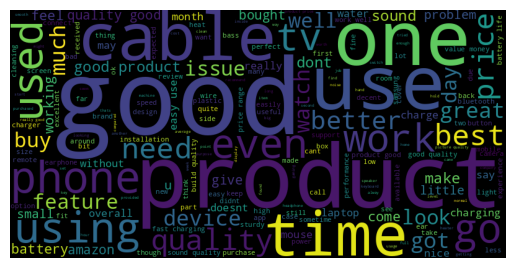

In [ ]:
# رسم Word Cloud للكلمات الأكثر تكرارًا
# Visualize most frequent words

from wordcloud import WordCloud
import matplotlib.pyplot as plt

# تحويل الكلمات إلى نص واحد
# Convert list of words into one string
text_all = " ".join(all_words)

# إنشاء WordCloud
# Generate word cloud
wc = WordCloud(width=800, height=400).generate(text_all)

# عرض الصورة
# Display the word cloud
plt.imshow(wc)
plt.axis('off')
plt.show()


The Word Cloud shows the most frequent words in the reviews.

We can observe that words like "product", "good", "use", and "time" appear larger, which means they are mentioned more often by users.

This indicates that customers mainly talk about the product quality, usability, and performance over time.

Also, words like "price", "work", and "best" suggest that users are discussing value, functionality, and satisfaction.

Overall, the Word Cloud helps us quickly understand the main topics and focus areas in customer reviews.

يعرض الـ Word Cloud أكثر الكلمات تكرارًا في التقييمات.

نلاحظ أن كلمات مثل "product" و "good" و "use" و "time" تظهر بحجم أكبر، وهذا يدل على أنها الأكثر استخدامًا في المراجعات.

هذا يعني أن المستخدمين يركزون بشكل أساسي على جودة المنتج، سهولة الاستخدام، وأداء المنتج مع الوقت.

كما أن كلمات مثل "price" و "work" و "best" تشير إلى أن العملاء يهتمون بالسعر وكفاءة المنتج ومدى رضاهم عنه.

بشكل عام، يساعدنا Word Cloud على فهم أهم المواضيع في التقييمات بسرعة.



---



 TF-IDF Feature Extraction

: استخراج الخصائص باستخدام TF-IDF

In [ ]:
# =========================================
# Create sentiment labels from rating
# إنشاء تصنيف المشاعر باستخدام التقييم
# =========================================

# Ensure 'rating' column is numeric before comparison
# Convert to string first to handle potential mixed types and then remove non-numeric chars like ',' or whitespace
df['rating'] = df['rating'].astype(str).str.replace(',', '').str.strip()
df['rating'] = pd.to_numeric(df['rating'], errors='coerce')

# Fill any NaN values (resulting from coercion of non-numeric data) with 0
# This ensures all ratings are numeric and will be classified as 'Negative' if missing or invalid.
df['rating'] = df['rating'].fillna(0)

df['sentiment'] = df['rating'].apply(lambda x: 'Positive' if x >= 4 else 'Negative')

# عرض عدد المراجعات في كل فئة
# Show number of reviews in each sentiment class
print(df['sentiment'].value_counts())

sentiment
Positive    1110
Negative     355
Name: count, dtype: int64


Apply TF-IDF

تطبيق TF-IDF

In [ ]:
# =========================================
# Import TF-IDF Vectorizer
# استيراد أداة TF-IDF
# =========================================

from sklearn.feature_extraction.text import TfidfVectorizer

# =========================================
# Apply TF-IDF on review text
# تطبيق TF-IDF على نصوص المراجعات
# =========================================

vectorizer = TfidfVectorizer(
    max_features=1000,
    stop_words='english'
)

X = vectorizer.fit_transform(df['review_content'].dropna())

# استخراج أسماء الكلمات
# Get feature names
feature_names = vectorizer.get_feature_names_out()

print("TF-IDF shape:", X.shape)

TF-IDF shape: (1465, 1000)


 Top Important Words using TF-IDF

أهم الكلمات باستخدام TF-IDF

In [ ]:
# =========================================
# Prepare data for comparison
# تجهيز البيانات للمقارنة
# =========================================

import numpy as np

b_df = df.dropna(subset=['review_content']).copy()

positive_idx = b_df['sentiment'] == 'Positive'
negative_idx = b_df['sentiment'] == 'Negative'

# =========================================
# Calculate average TF-IDF score
# حساب متوسط قيمة TF-IDF
# =========================================

# Convert pandas Series to numpy array for indexing sparse matrix X
pos_mean = X[positive_idx.to_numpy()].mean(axis=0)
neg_mean = X[negative_idx.to_numpy()].mean(axis=0)

# =========================================
# Get top 10 words
# استخراج أهم 10 كلمات
# =========================================

top_pos_idx = np.argsort(pos_mean.A1)[-10:]
top_neg_idx = np.argsort(neg_mean.A1)[-10:]

top_pos_words = [feature_names[i] for i in top_pos_idx]
top_neg_words = [feature_names[i] for i in top_neg_idx]

top_pos_scores = pos_mean.A1[top_pos_idx]
top_neg_scores = neg_mean.A1[top_neg_idx]

print("Top Positive Words:")
print(list(zip(top_pos_words, top_pos_scores)))

print("\nTop Negative Words:")
print(list(zip(top_neg_words, top_neg_scores)))

Top Positive Words:
[('like', np.float64(0.03545772570331452)), ('easy', np.float64(0.039487131593970035)), ('nice', np.float64(0.04021555430579255)), ('price', np.float64(0.040541182776702905)), ('use', np.float64(0.046770331453074486)), ('charging', np.float64(0.04910019220291466)), ('quality', np.float64(0.06166804374671662)), ('cable', np.float64(0.06586253426049464)), ('product', np.float64(0.09196429386864524)), ('good', np.float64(0.13396703859542564))]

Top Negative Words:
[('money', np.float64(0.03222730911227535)), ('water', np.float64(0.032887121347607545)), ('price', np.float64(0.039964206357426806)), ('remote', np.float64(0.04180279614360314)), ('working', np.float64(0.043215471387368525)), ('nice', np.float64(0.04681377045340574)), ('use', np.float64(0.04732347783486636)), ('quality', np.float64(0.053512671804230964)), ('product', np.float64(0.09675842464497587)), ('good', np.float64(0.12115473797120382))]


 Visualization of TF-IDF Results

عرض النتائج باستخدام الرسوم البيانية

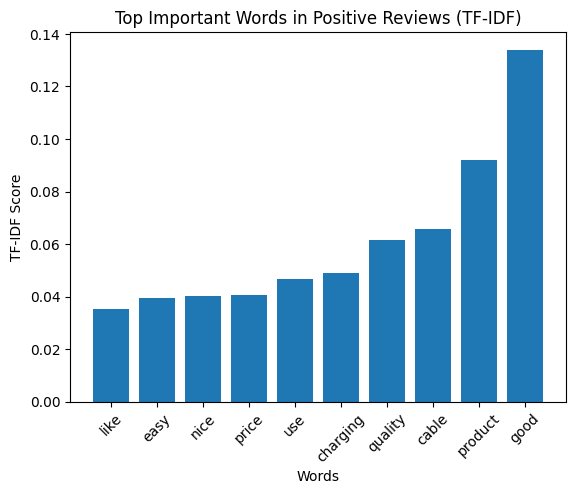

In [ ]:
# =========================================
# Visualize positive TF-IDF words
# رسم الكلمات المهمة في المراجعات الإيجابية
# =========================================

import matplotlib.pyplot as plt

plt.bar(top_pos_words, top_pos_scores)
plt.title("Top Important Words in Positive Reviews (TF-IDF)")
plt.xlabel("Words")
plt.ylabel("TF-IDF Score")
plt.xticks(rotation=45)
plt.show()

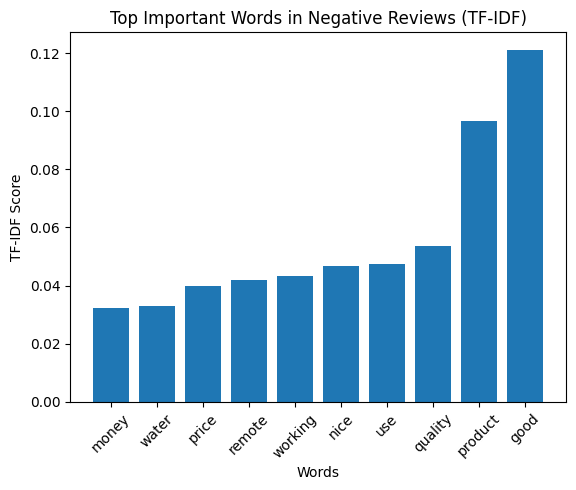

In [ ]:
# =========================================
# Visualize negative TF-IDF words
# رسم الكلمات المهمة في المراجعات السلبية
# =========================================

plt.bar(top_neg_words, top_neg_scores)
plt.title("Top Important Words in Negative Reviews (TF-IDF)")
plt.xlabel("Words")
plt.ylabel("TF-IDF Score")
plt.xticks(rotation=45)
plt.show()

Positive reviews focus on satisfaction words like "good", "easy", and "quality".

Negative reviews focus more on issues related to "price", "product", and "usage problems".

المراجعات الإيجابية تركز على كلمات تعبر عن الرضا مثل: good و easy و quality.

المراجعات السلبية تركز على المشاكل مثل: السعر (price) والمنتج (product) وطريقة الاستخدام.





##Final Analysis

After text preprocessing, the review text became cleaner and more suitable for analysis. Uppercase and lowercase words were standardized, punctuation and common stopwords were removed, and words were tokenized and lemmatized. This reduced noise in the text and helped extract more meaningful words for WordCloud and TF-IDF analysis.

بعد معالجة النصوص، أصبحت المراجعات أنظف وأكثر مناسبة للتحليل. تم توحيد الحروف، إزالة علامات الترقيم والكلمات الشائعة، ثم تقسيم النصوص إلى كلمات وإرجاع الكلمات إلى أصلها. ساعد ذلك في تقليل الضوضاء واستخراج كلمات أكثر معنى في تحليل WordCloud و TF-IDF.

By comparing TF-IDF results for both positive and negative reviews, we observe that positive reviews focus on user satisfaction aspects such as ease of use, quality, and overall product experience.

In contrast, negative reviews tend to highlight concerns related to product issues, pricing, and performance. Interestingly, some words like "good" and "nice" appear in both positive and negative reviews. However, this does not necessarily indicate the same sentiment. In many negative reviews, these words are used within contrasting statements, such as “the product is good, but it has problems” or “it looks nice, but it does not work properly.”

This indicates that customers may initially express a positive impression, but then mention specific issues related to functionality, price, or usability. Therefore, TF-IDF considers these words important because they frequently appear in meaningful contexts, even if the overall sentiment of the review is negative.

This comparison provides a deeper understanding of customer feedback by distinguishing between satisfaction drivers and common complaints, while also highlighting the importance of analyzing the full context rather than relying only on individual words.
  
من خلال مقارنة نتائج TF-IDF  نلاحظ أن

يبن المراجعات الإيجابية والسلبية،
المراجعات الإيجابية تركز على رضا المستخدم مثل سهولة الاستخدام والجودة وتجربة المنتج بشكل عام.  

 تركز المراجعات السلبية على المشكلات مثل عيوب المنتج والسعر والأداء.
  
 وفي المقابل
 الملاحظ أن بعض الكلمات مثل "good" و "nice" تظهر في كلا النوعين من المراجعات
 ولكن هذا لا يعني أنها تحمل نفس المعنى. ففي كثير من المراجعات السلبية تُستخدم هذه الكلمات في سياق المقارنة أو التناقض، مثل: "المنتج جيد ولكن به مشاكل" أو "يبدو جيدًا لكنه لا يعمل بشكل صحيح".  

وهذا يدل على أن المستخدم قد يبدأ بانطباع إيجابي ثم يذكر مشكلات محددة تتعلق بالأداء أو السعر أو سهولة الاستخدام. لذلك، تعتبر طريقة TF-IDF هذه الكلمات مهمة لأنها تتكرر في سياقات ذات معنى، حتى وإن كان التقييم العام سلبيًا.  

بشكل عام، تساعد هذه المقارنة في فهم أعمق لآراء المستخدمين من خلال التمييز بين عوامل الرضا والمشكلات الشائعة، مع التأكيد على أهمية تحليل السياق الكامل للنص وليس الاعتماد فقط على الكلمات المفرد